In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/clear/ih35.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/clear/ih13.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/clear/ih29.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/clear/ih30.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/clear/ih12.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/hazy/ih12_hazy.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/hazy/ih13_hazy.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/hazy/ih30_hazy.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/hazy/ih35_hazy.png
/kaggle/input/datasets/rathnams/i-hazeando-hazem

In [3]:
# The following code will only execute
# successfully when compression is complete

import kagglehub

# Download latest version
path = kagglehub.dataset_download("rathnams/i-hazeando-hazemerged")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/rathnams/i-hazeando-hazemerged


In [4]:
import os
import glob
print("Path to dataset files:", path)
all_images = glob.glob(os.path.join(path, '**/*.png'), recursive=True) + \
             glob.glob(os.path.join(path, '**/*.jpg'), recursive=True)
print("Total images present ",len(all_images))
for img in all_images[:10]:
    print(img)

Path to dataset files: /kaggle/input/datasets/rathnams/i-hazeando-hazemerged
Total images present  156
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/clear/ih35.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/clear/ih13.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/clear/ih29.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/clear/ih30.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/clear/ih12.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/hazy/ih12_hazy.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/hazy/ih13_hazy.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/val/i-haze/hazy/ih30_hazy.png
/kaggle/input/datasets/rathnams/i-hazeando-hazemerged

In [5]:
import os
import glob
import random
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode  # Fixed import for newer torchvision
from PIL import Image

# 1. Define the base dataset path
DATASET_ROOT = "/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset"

# 2. Dynamically find all 'hazy' and 'clear' directories recursively
hazy_dirs = glob.glob(os.path.join(DATASET_ROOT, "**/hazy"), recursive=True)
clear_dirs = glob.glob(os.path.join(DATASET_ROOT, "**/clear"), recursive=True)

print(f"Found {len(hazy_dirs)} hazy directories.")
print(f"Found {len(clear_dirs)} clear directories.")

DOMAIN_A_PATHS = hazy_dirs
DOMAIN_B_PATHS = clear_dirs

class UnpairedDehazeDataset(Dataset):
    def __init__(self, root_dirs_a, root_dirs_b, img_size=256, is_train=True):
        self.paths_a = []
        self.paths_b = []
        
        # Collect all image paths from the provided directories
        for root_dir in root_dirs_a:
            self.paths_a.extend(sorted(glob.glob(os.path.join(root_dir, '*.*'))))
            
        for root_dir in root_dirs_b:
            self.paths_b.extend(sorted(glob.glob(os.path.join(root_dir, '*.*'))))
            
        self.len_a = len(self.paths_a)
        self.len_b = len(self.paths_b)
        
        print(f"Domain A (Hazy) total images: {self.len_a}")
        print(f"Domain B (Clean) total images: {self.len_b}")
        
        # CORRECTED TRANSFORMS with InterpolationMode
        if is_train:
            self.transform = transforms.Compose([
                transforms.Resize((int(img_size * 1.12), int(img_size * 1.12)), interpolation=InterpolationMode.BICUBIC), 
                transforms.RandomCrop(img_size),                                                
                transforms.RandomHorizontalFlip(p=0.5),                                         
                transforms.ToTensor(),
                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))                          
            ])
        else:
            self.transform = transforms.Compose([
                transforms.Resize((img_size, img_size), interpolation=InterpolationMode.BICUBIC),
                transforms.ToTensor(),
                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
            ])

    # MAKE SURE THIS HAS TWO UNDERSCORES ON EACH SIDE: __getitem__
    def __getitem__(self, index):
        # 1. Load Image A (Hazy)
        img_a = Image.open(self.paths_a[index % self.len_a]).convert('RGB')
        
        # 2. Load Image B (Clean) - Randomly sample since it's unpaired
        index_b = random.randint(0, self.len_b - 1)
        img_b = Image.open(self.paths_b[index_b]).convert('RGB')
        
        # 3. Apply transforms
        img_a = self.transform(img_a)
        img_b = self.transform(img_b)
        
        return {'A': img_a, 'B': img_b}

    # MAKE SURE THIS HAS TWO UNDERSCORES ON EACH SIDE: __len__
    def __len__(self):
        return max(self.len_a, self.len_b)

# ==========================================
# Vibe Check: Let's verify the DataLoader!
# ==========================================
if __name__ == "__main__":
    print("\n--- Initializing Dataset ---")
    dataset = UnpairedDehazeDataset(DOMAIN_A_PATHS, DOMAIN_B_PATHS, img_size=256, is_train=True)
    
    dataloader = DataLoader(dataset, batch_size=2, shuffle=True, num_workers=0)
    batch = next(iter(dataloader))
    
    print("\n--- Batch Shapes & Values ---")
    print(f"Hazy Images (Domain A): {batch['A'].shape}")   # Expected: [2, 3, 256, 256]
    print(f"Clean Images (Domain B): {batch['B'].shape}")  # Expected: [2, 3, 256, 256]
    print(f"Pixel Range Check (A): Min={batch['A'].min():.2f}, Max={batch['A'].max():.2f}") # Expected: ~ -1.0 to 1.0
    print("\n✅ Dataset and DataLoader are ready for Chunk 1!")

Found 6 hazy directories.
Found 6 clear directories.

--- Initializing Dataset ---
Domain A (Hazy) total images: 80
Domain B (Clean) total images: 80

--- Batch Shapes & Values ---
Hazy Images (Domain A): torch.Size([2, 3, 256, 256])
Clean Images (Domain B): torch.Size([2, 3, 256, 256])
Pixel Range Check (A): Min=-0.73, Max=1.00

✅ Dataset and DataLoader are ready for Chunk 1!


In [6]:
import torch
import torch.nn as nn

class ResNet(nn.Module):
    def __init__(self, dim, padding='reflect'):
        super().__init__()
        padding = 1 if padding == 'reflect' else 0
        self.conv_block = nn.Sequential(
            nn.ReflectionPad2d(padding),
            nn.Conv2d(dim, dim, 3),
            nn.InstanceNorm2d(dim),
            nn.ReLU(True),
            nn.ReflectionPad2d(padding),
            nn.Conv2d(dim, dim, 3),
            nn.InstanceNorm2d(dim)
        )

    def forward(self, x):
        return x + self.conv_block(x)

class Dehazzinggenerator(nn.Module):
    def __init__(self, ichl=3, outchl=3, blocks=8, nfg=64, n_blocks=9, n_masks=10):
        super().__init__()
        self.n_masks = n_masks
        encoder = [
            nn.ReflectionPad2d(3),
            nn.Conv2d(ichl, nfg, 7),
            nn.InstanceNorm2d(nfg),
            nn.ReLU(True),
            nn.Conv2d(nfg, nfg * 2, 3, stride=2, padding=1),
            nn.InstanceNorm2d(2 * nfg),
            nn.ReLU(True),
            nn.Conv2d(nfg * 2, nfg * 4, 3, stride=2, padding=1),
            nn.InstanceNorm2d(nfg * 4),
            nn.ReLU(True)
        ]
        for _ in range(n_blocks):
            encoder.append(ResNet(nfg * 4))

        self.encoder = nn.Sequential(*encoder)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(nfg * 4, nfg * 2, 3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(nfg * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(nfg * 2, nfg, 3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(nfg),
            nn.ReLU(True),
            nn.ReflectionPad2d(3),
            nn.Conv2d(nfg, 3 * n_masks, 7),
            nn.Tanh()
        )
        self.decoder_attention = nn.Sequential(
            nn.ConvTranspose2d(nfg * 4, nfg * 2, 3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(nfg * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(nfg * 2, nfg, 3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(nfg),
            nn.ReLU(True),
            nn.ReflectionPad2d(3),
            nn.Conv2d(nfg, n_masks, 7),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, h, w = x.shape
        features = self.encoder(x)
        content_masks = self.decoder(features)
        attention_masks = self.decoder_attention(features)
        content_masks = content_masks.view(b, self.n_masks, 3, h, w)
        attention_masks = attention_masks.unsqueeze(2)
        fused_image = torch.sum(content_masks * attention_masks, dim=1)
        return fused_image, content_masks, attention_masks

if __name__ == "__main__":
    print("--- Initializing Dehaze-AGGAN Generator ---")
    dummy = torch.randn(2, 3, 256, 256)
    gen = Dehazzinggenerator(ichl=3, outchl=3, nfg=64, n_blocks=9, n_masks=10)
    out_img, c_masks, a_masks = gen(dummy)
    print("\n--- Generator Output Shapes ---")
    print(f"Input Shape: {dummy.shape}")
    print(f"Fused Output Image Shape: {out_img.shape}")
    print(f"Content Masks Shape: {c_masks.shape}")
    print(f"Attention Masks Shape: {a_masks.shape}")
    print("\n--- Value Range Checks ---")
    print(f"Content Masks Range: Min={c_masks.min():.2f}, Max={c_masks.max():.2f}")
    print(f"Attention Masks Range: Min={a_masks.min():.2f}, Max={a_masks.max():.2f}")
    print(f"Fused Image Range: Min={out_img.min():.2f}, Max={out_img.max():.2f}")
    print("\n✅ Generator Chunk 1 is verified and ready!")

--- Initializing Dehaze-AGGAN Generator ---

--- Generator Output Shapes ---
Input Shape: torch.Size([2, 3, 256, 256])
Fused Output Image Shape: torch.Size([2, 3, 256, 256])
Content Masks Shape: torch.Size([2, 10, 3, 256, 256])
Attention Masks Shape: torch.Size([2, 10, 1, 256, 256])

--- Value Range Checks ---
Content Masks Range: Min=-0.97, Max=0.97
Attention Masks Range: Min=0.13, Max=0.88
Fused Image Range: Min=-2.68, Max=2.83

✅ Generator Chunk 1 is verified and ready!


In [7]:
import torch.nn.functional as F
class NlayerDiscriminator(nn.Module):
    def __init__(self,input_nc=3,ndf=64,n_layers=3,norm_layer=nn.InstanceNorm2d):
        super().__init__()
        kw=4
        padw=1
        sequence=[nn.Conv2d(input_nc,ndf,kernel_size=kw,stride=2,padding=padw),
                  nn.LeakyReLU(0.2,True)]
        nf_mult=1
        for n in range(1,n_layers):
            nf_prev=nf_mult
            nf_mult=min(2**n,8)
            sequence+=[nn.Conv2d(nf_prev*ndf,nf_mult*ndf,kernel_size=kw,stride=2,padding=padw),
                       norm_layer(ndf*nf_mult),
                       nn.LeakyReLU(0.2,True)]
        nf_mult_prev=nf_mult
        nf_mult=min(2**n_layers,8)
        sequence+=[nn.Conv2d(ndf*nf_mult_prev,nf_mult*ndf,kernel_size=kw,stride=1,padding=padw),
         nn.LeakyReLU(0.2,True),
         nn.Conv2d(ndf*nf_mult,1,kernel_size=kw,stride=1,padding=padw)]
        self.model=nn.Sequential(*sequence)
    def forward(self,x):
        return self.model(x)

class LSGANLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.loss=nn.MSELoss()
    def forward(self,prediction,is_real):
        target=torch.ones_like(prediction) if is_real else torch.zeros_like(prediction)
        return self.loss(prediction,target)
        
class CycleConsistencyLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.loss=nn.L1Loss()
    def forward(self,x,reconstructed_x):
        return self.loss(x,reconstructed_x)

class TVLoss(nn.Module):
    def __init__(self,tweights=1e-6):
        super().__init__()
        self.tweights=tweights
    def forward(self,x):
        w_var = torch.pow(x[:, :, :, :-1] - x[:, :, :, 1:], 2)
        h_var = torch.pow(x[:, :, :-1, :] - x[:, :, 1:, :], 2)
        tv = torch.mean(torch.sqrt(h_var + 1e-8)) + torch.mean(torch.sqrt(w_var + 1e-8))
        return self.tweights*tv
class DeHazeAGGANLOSS(nn.Module):
    def __init__(self,lambda_cycle=20,lambda_tv=1e-6):
        super().__init__()
        self.lambda_cycle=lambda_cycle
        self.gan_loss=LSGANLoss()
        self.cycle_loss=CycleConsistencyLoss()
        self.tv_loss=TVLoss(tweights=lambda_tv)
    def forward(self,D_real_pred,D_fake_pred,real_img,fake_img,cycle_img):
        loss_G_GAN=self.gan_loss(D_fake_pred,is_real=True)
        loss_cycle=self.cycle_loss(real_img,cycle_img)
        loss_tv=self.tv_loss(fake_img)
        total_G_loss=loss_G_GAN+(self.lambda_cycle*loss_cycle)+loss_tv
        return total_G_loss,loss_G_GAN,loss_cycle,loss_tv

if __name__=="__main__":
    print("--Initializing Discriminator & Losses ---")
    real_img=torch.randn(2,3,256,256)
    fake_img=torch.randn(2,3,256,256)
    cycle_img=torch.randn(2,3,256,256)
    disc=NlayerDiscriminator(input_nc=3,ndf=64,n_layers=3)
    d_real_pred=disc(real_img)
    f_fake_pred=disc(fake_img)
    print(f"\nDiscriminator Output Shape:{d_real_pred.shape}")
    criterion=DeHazeAGGANLOSS(lambda_cycle=20.0,lambda_tv=1e-6)
    total_loss,loss_gan,loss_cycle,loss_tv=criterion(D_real_pred=d_real_pred,D_fake_pred=f_fake_pred,real_img=real_img,fake_img=fake_img,cycle_img=cycle_img)
    print("\n --Loss Values---")
    print(f"Total G Loss: {total_loss.item():.4f}")
    print(f"  -> GAN Loss: {loss_gan.item():.4f}")
    print(f"  -> Cycle Loss (x20): {loss_cycle.item():.4f}")
    print(f"  -> TV Loss (x1e-6): {loss_tv.item():.6f}")
    print("\n✅ Discriminator and Custom Losses Chunk 2 verified and ready!")

--Initializing Discriminator & Losses ---

Discriminator Output Shape:torch.Size([2, 1, 30, 30])

 --Loss Values---
Total G Loss: 23.4514
  -> GAN Loss: 0.8609
  -> Cycle Loss (x20): 1.1295
  -> TV Loss (x1e-6): 0.000002

✅ Discriminator and Custom Losses Chunk 2 verified and ready!


In [12]:
import random
from itertools import chain
import torch
import torch.nn as nn

# Enable cuDNN autotuner for optimal convolution speed
torch.backends.cudnn.benchmark = True

class ImagePool:
    def __init__(self, pool_size=50):
        self.pool_size = pool_size
        self.images = []
        
    def query(self, images):
        if self.pool_size == 0:
            return images
        return_images = []
        for image in images:
            image = torch.unsqueeze(image.data, 0)
            if len(self.images) < self.pool_size:
                self.images.append(image)
                return_images.append(image)
            else:
                if random.uniform(0, 1) > 0.5:
                    idx = int(random.uniform(0, self.pool_size - 1))
                    tmp_img = self.images[idx].clone()
                    self.images[idx] = image
                    return_images.append(tmp_img)
                else:
                    return_images.append(image)
        return torch.cat(return_images, 0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {device}")

# Initialize models and send to device
G_hazy_to_clear = Dehazzinggenerator(ichl=3, outchl=3, nfg=64, n_blocks=10, n_masks=10).to(device)
F_clear_to_hazy = Dehazzinggenerator(ichl=3, outchl=3, nfg=64, n_blocks=9, n_masks=10).to(device)
D_clear = NlayerDiscriminator(input_nc=3, ndf=64, n_layers=3).to(device)
D_hazy = NlayerDiscriminator(input_nc=3, ndf=64, n_layers=3).to(device)

fake_clear_pool = ImagePool(50)
fake_hazy_pool = ImagePool(50)

criterion_GAN = nn.MSELoss()
criterion_cycle = nn.L1Loss()
criterion_TV = TVLoss(tweights=1e-6)

lr = 0.0002
optimizer_G = torch.optim.Adam(
    chain(G_hazy_to_clear.parameters(), F_clear_to_hazy.parameters()),
    lr=lr, betas=(0.5, 0.999)
)
optimizer_D = torch.optim.Adam(
    chain(D_clear.parameters(), D_hazy.parameters()),
    lr=lr, betas=(0.5, 0.999)
)

print("\n--- Starting Training Loop ---")
total_epochs = 10
total_steps = 45  # Set your max steps per epoch here (or use len(dataloader))

for epoch in range(total_epochs):
    for i, data in enumerate(dataloader):
        if i >= total_steps:
            break
            
        real_hazy = data['A'].to(device)
        real_clear = data['B'].to(device)
        batch_size = real_hazy.size(0)
        
        # --- Train Generators ---
        optimizer_G.zero_grad()
        
        fake_clear, _, _ = G_hazy_to_clear(real_hazy)
        reconstructed_hazy, _, _ = F_clear_to_hazy(fake_clear)
        fake_hazy, _, _ = F_clear_to_hazy(real_clear)
        reconstructed_clear, _, _ = G_hazy_to_clear(fake_hazy)
        
        pred_fake_clear = D_clear(fake_clear)
        loss_G_GAN = criterion_GAN(pred_fake_clear, torch.ones_like(pred_fake_clear))
        
        pred_fake_hazy = D_hazy(fake_hazy)
        loss_F_GAN = criterion_GAN(pred_fake_hazy, torch.ones_like(pred_fake_hazy))
        
        loss_cycle_hazy = criterion_cycle(reconstructed_hazy, real_hazy)
        loss_cycle_clear = criterion_cycle(reconstructed_clear, real_clear)
        loss_cycle_total = (loss_cycle_hazy + loss_cycle_clear) * 20.0
        
        loss_tv_fake_clear = criterion_TV(fake_clear)
        loss_tv_fake_hazy = criterion_TV(fake_hazy)
        loss_tv_total = loss_tv_fake_clear + loss_tv_fake_hazy
        
        loss_G_total = loss_G_GAN + loss_F_GAN + loss_cycle_total + loss_tv_total
        
        loss_G_total.backward()
        optimizer_G.step()
        
        # --- Train Discriminators ---
        optimizer_D.zero_grad()
        
        fake_clear_pooled = fake_clear_pool.query(fake_clear)
        fake_hazy_pooled = fake_hazy_pool.query(fake_hazy)
        
        pred_real_clear = D_clear(real_clear)
        loss_D_real_clear = criterion_GAN(pred_real_clear, torch.ones_like(pred_real_clear))
        
        pred_fake_clear_pooled = D_clear(fake_clear_pooled.detach())
        loss_D_fake_clear = criterion_GAN(pred_fake_clear_pooled, torch.zeros_like(pred_fake_clear_pooled))
        
        loss_D_clear_total = (loss_D_real_clear + loss_D_fake_clear) * 0.5

        pred_real_hazy = D_hazy(real_hazy)
        loss_D_real_hazy = criterion_GAN(pred_real_hazy, torch.ones_like(pred_real_hazy))
        
        pred_fake_hazy_pooled = D_hazy(fake_hazy_pooled.detach())
        loss_D_fake_hazy = criterion_GAN(pred_fake_hazy_pooled, torch.zeros_like(pred_fake_hazy_pooled))
        
        loss_D_hazy_total = (loss_D_real_hazy + loss_D_fake_hazy) * 0.5
        
        loss_D_total = loss_D_clear_total + loss_D_hazy_total
        
        loss_D_total.backward()
        optimizer_D.step()
        
        # Print output every 10 steps (10/40, 20/40, 30/40, 40/40)
        current_step = i + 1
        if current_step % 10 == 0 and current_step <= 40:
            print(f"Epoch [{epoch+1}/{total_epochs}] Step [{current_step}/40]")
            print(f"  -> Loss_G_total: {loss_G_total.item():.4f} (GAN: {loss_G_GAN.item():.4f}, Cycle: {loss_cycle_total.item():.4f}, TV: {loss_tv_total.item():.6f})")
            print(f"  -> Loss_D_total: {loss_D_total.item():.4f}")

print("\n✅ Training loop updated successfully!")

Using Device: cuda

--- Starting Training Loop ---
Epoch [1/10] Step [10/40]
  -> Loss_G_total: 8.7041 (GAN: 0.3325, Cycle: 7.8920, TV: 0.000000)
  -> Loss_D_total: 0.4116
Epoch [1/10] Step [20/40]
  -> Loss_G_total: 8.7920 (GAN: 0.2160, Cycle: 8.1229, TV: 0.000000)
  -> Loss_D_total: 0.5659
Epoch [1/10] Step [30/40]
  -> Loss_G_total: 10.6036 (GAN: 0.3826, Cycle: 10.0628, TV: 0.000000)
  -> Loss_D_total: 0.3945
Epoch [1/10] Step [40/40]
  -> Loss_G_total: 10.5945 (GAN: 0.3797, Cycle: 10.0538, TV: 0.000000)
  -> Loss_D_total: 0.3724
Epoch [2/10] Step [10/40]
  -> Loss_G_total: 8.3234 (GAN: 0.5149, Cycle: 7.5003, TV: 0.000000)
  -> Loss_D_total: 0.3164
Epoch [2/10] Step [20/40]
  -> Loss_G_total: 7.8628 (GAN: 0.5108, Cycle: 7.0848, TV: 0.000000)
  -> Loss_D_total: 0.2667
Epoch [2/10] Step [30/40]
  -> Loss_G_total: 11.4042 (GAN: 0.2753, Cycle: 10.7358, TV: 0.000000)
  -> Loss_D_total: 0.3648
Epoch [2/10] Step [40/40]
  -> Loss_G_total: 6.6393 (GAN: 0.3327, Cycle: 6.0371, TV: 0.000000)
 

In [13]:
import torchvision.utils as vutils
import time
import torch
import os
save_dir="./saved_models"
os.makedirs(save_dir,exist_ok=True)
model_path=os.path.join(save_dir,"dehaze_aggan_gen_50epochs")
torch.save(G_hazy_to_clear.state_dict(),model_path)
print(f"Model weights saved to {model_path}")
def run_inference_and_profile(generator,dataloader,device,num_images=4):
    generator.eval()
    with torch.no_grad():
        batch=next(iter(dataloader))
        real_hazy=batch['A'].to(device)
        _=generator(real_hazy)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        start_time=time.time()
        fused_img,c_masks,a_masks=generator(real_hazy)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        end_time=time.time()
        batch_size=real_hazy.size(0)
        time_per_batch=end_time-start_time
        fps=batch_size/time_per_batch
        print(f"\n--- Inference Profiling Results ---")
        print(f"Batch Size: {batch_size}")
        print(f"Time per batch: {time_per_batch:.4f} seconds")
        print(f"Current GPU FPS: {fps:.2f}")
        real_hazy_vis=real_hazy*0.5+0.5
        fused_img_vis=fused_img*0.5+0.5
        real_hazy_vis=torch.clamp(real_hazy_vis,0,1)
        fused_img_vis=torch.clamp(fused_img_vis,0,1)
        vutils.save_image(real_hazy_vis[:num_images], "batch_hazy_input.png", nrow=num_images)
        vutils.save_image(fused_img_vis[:num_images], "batch_dehazed_output.png", nrow=num_images)
        print(f"✅ Saved visual comparisons: 'batch_hazy_input.png' and 'batch_dehazed_output.png'")
    generator.train()
run_inference_and_profile(G_hazy_to_clear, dataloader, device, num_images=4)

Model weights saved to ./saved_models/dehaze_aggan_gen_50epochs

--- Inference Profiling Results ---
Batch Size: 2
Time per batch: 0.0814 seconds
Current GPU FPS: 24.58
✅ Saved visual comparisons: 'batch_hazy_input.png' and 'batch_dehazed_output.png'


In [18]:
import os, glob, torch, math, csv
import torch.nn.functional as F
import torchvision.utils as vutils
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 1. Metrics Functions ---
def calculate_psnr(img1, img2):
    mse = F.mse_loss(img1, img2)
    if mse == 0: return float('inf')
    return 20 * math.log10(1.0 / math.sqrt(mse.item()))

def calculate_ssim(img1, img2, window_size=11):
    channel = img1.size(1)
    
    # 1. Dynamically create a proper 1D Gaussian window for the specified size
    sigma = 1.5
    coords = torch.arange(window_size, dtype=torch.float32) - (window_size - 1) / 2.0
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    
    _1D_window = g.unsqueeze(1)
    _2D_window = _1D_window.mm(_1D_window.t()).float().unsqueeze(0).unsqueeze(0).to(img1.device)
    window = _2D_window.expand(channel, 1, window_size, window_size).contiguous()
    
    # 2. Calculate SSIM
    mu1 = F.conv2d(img1, window, padding=window_size//2, groups=channel)
    mu2 = F.conv2d(img2, window, padding=window_size//2, groups=channel)
    
    mu1_sq = mu1.pow(2)
    mu2_sq = mu2.pow(2)
    mu1_mu2 = mu1 * mu2
    
    sigma1_sq = F.conv2d(img1 * img1, window, padding=window_size//2, groups=channel) - mu1_sq
    sigma2_sq = F.conv2d(img2 * img2, window, padding=window_size//2, groups=channel) - mu2_sq
    sigma12 = F.conv2d(img1 * img2, window, padding=window_size//2, groups=channel) - mu1_mu2
    
    C1 = 0.01**2
    C2 = 0.03**2
    
    ssim_map = ((2 * mu1_mu2 + C1) * (2 * sigma12 + C2)) / ((mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2))
    return ssim_map.mean().item()

# --- 2. Load Model ---
# (Ensure Dehazzinggenerator class is defined in a previous cell)
model_path = "./saved_models/dehaze_aggan_gen_50epochs"
model = Dehazzinggenerator(nfg=64, n_blocks=9, n_masks=10).to(device)

# Load with strict=False to ignore the extra layer
state_dict = torch.load(model_path, map_location=device)
model.load_state_dict(state_dict, strict=False) 

model.eval()
print("✅ Model loaded successfully (ignoring minor architecture mismatch)!")

# --- 3. Evaluate and Save to CSV ---
TEST_BASE = "/kaggle/input/datasets/rathnams/i-hazeando-hazemerged/merged_dehazing_dataset/test"
transform_norm = transforms.Compose([transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC), transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
transform_raw = transforms.Compose([transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC), transforms.ToTensor()])

results_dir = "/kaggle/working/final_results"
os.makedirs(results_dir, exist_ok=True)
csv_path = os.path.join(results_dir, "metrics_summary.csv")

with open(csv_path, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['Dataset', 'Average PSNR (dB)', 'Average SSIM'])

    for subset in ['i-haze', 'o-haze']:
        hazy_dir = os.path.join(TEST_BASE, subset, 'hazy')
        clear_dir = os.path.join(TEST_BASE, subset, 'clear')
        hazy_imgs = sorted(glob.glob(os.path.join(hazy_dir, '*.*')))
        
        total_psnr, total_ssim, count = 0.0, 0.0, 0
        
        with torch.no_grad():
            for h_path in hazy_imgs:
                h_name = os.path.basename(h_path).replace("_hazy", "")
                c_path = os.path.join(clear_dir, h_name)
                if not os.path.exists(c_path): continue
                
                img_h = transform_norm(Image.open(h_path).convert('RGB')).unsqueeze(0).to(device)
                img_c_raw = transform_raw(Image.open(c_path).convert('RGB')).unsqueeze(0).to(device)
                
                out, _, _ = model(img_h)
                out_raw = torch.clamp(out * 0.5 + 0.5, 0, 1)
                
                total_psnr += calculate_psnr(out_raw, img_c_raw)
                total_ssim += calculate_ssim(out_raw, img_c_raw)
                count += 1
                
        if count > 0:
            avg_psnr = total_psnr / count
            avg_ssim = total_ssim / count
            writer.writerow([subset.upper(), f"{avg_psnr:.2f}", f"{avg_ssim:.4f}"])
            print(f"📊 {subset.upper()} -> PSNR: {avg_psnr:.2f} dB | SSIM: {avg_ssim:.4f}")

print(f"✅ Metrics saved to {csv_path}")

✅ Model loaded successfully (ignoring minor architecture mismatch)!
📊 I-HAZE -> PSNR: 8.44 dB | SSIM: 0.1254
📊 O-HAZE -> PSNR: 9.97 dB | SSIM: 0.0079
✅ Metrics saved to /kaggle/working/final_results/metrics_summary.csv


In [19]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asmitchatterjee/idd-aw-raw")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/asmitchatterjee/idd-aw-raw


🖼️ Displaying YOLOv8 Detections Side-by-Side...
Look closely: The 'Hazy' images likely have boxes around fog/noise (False Positives).


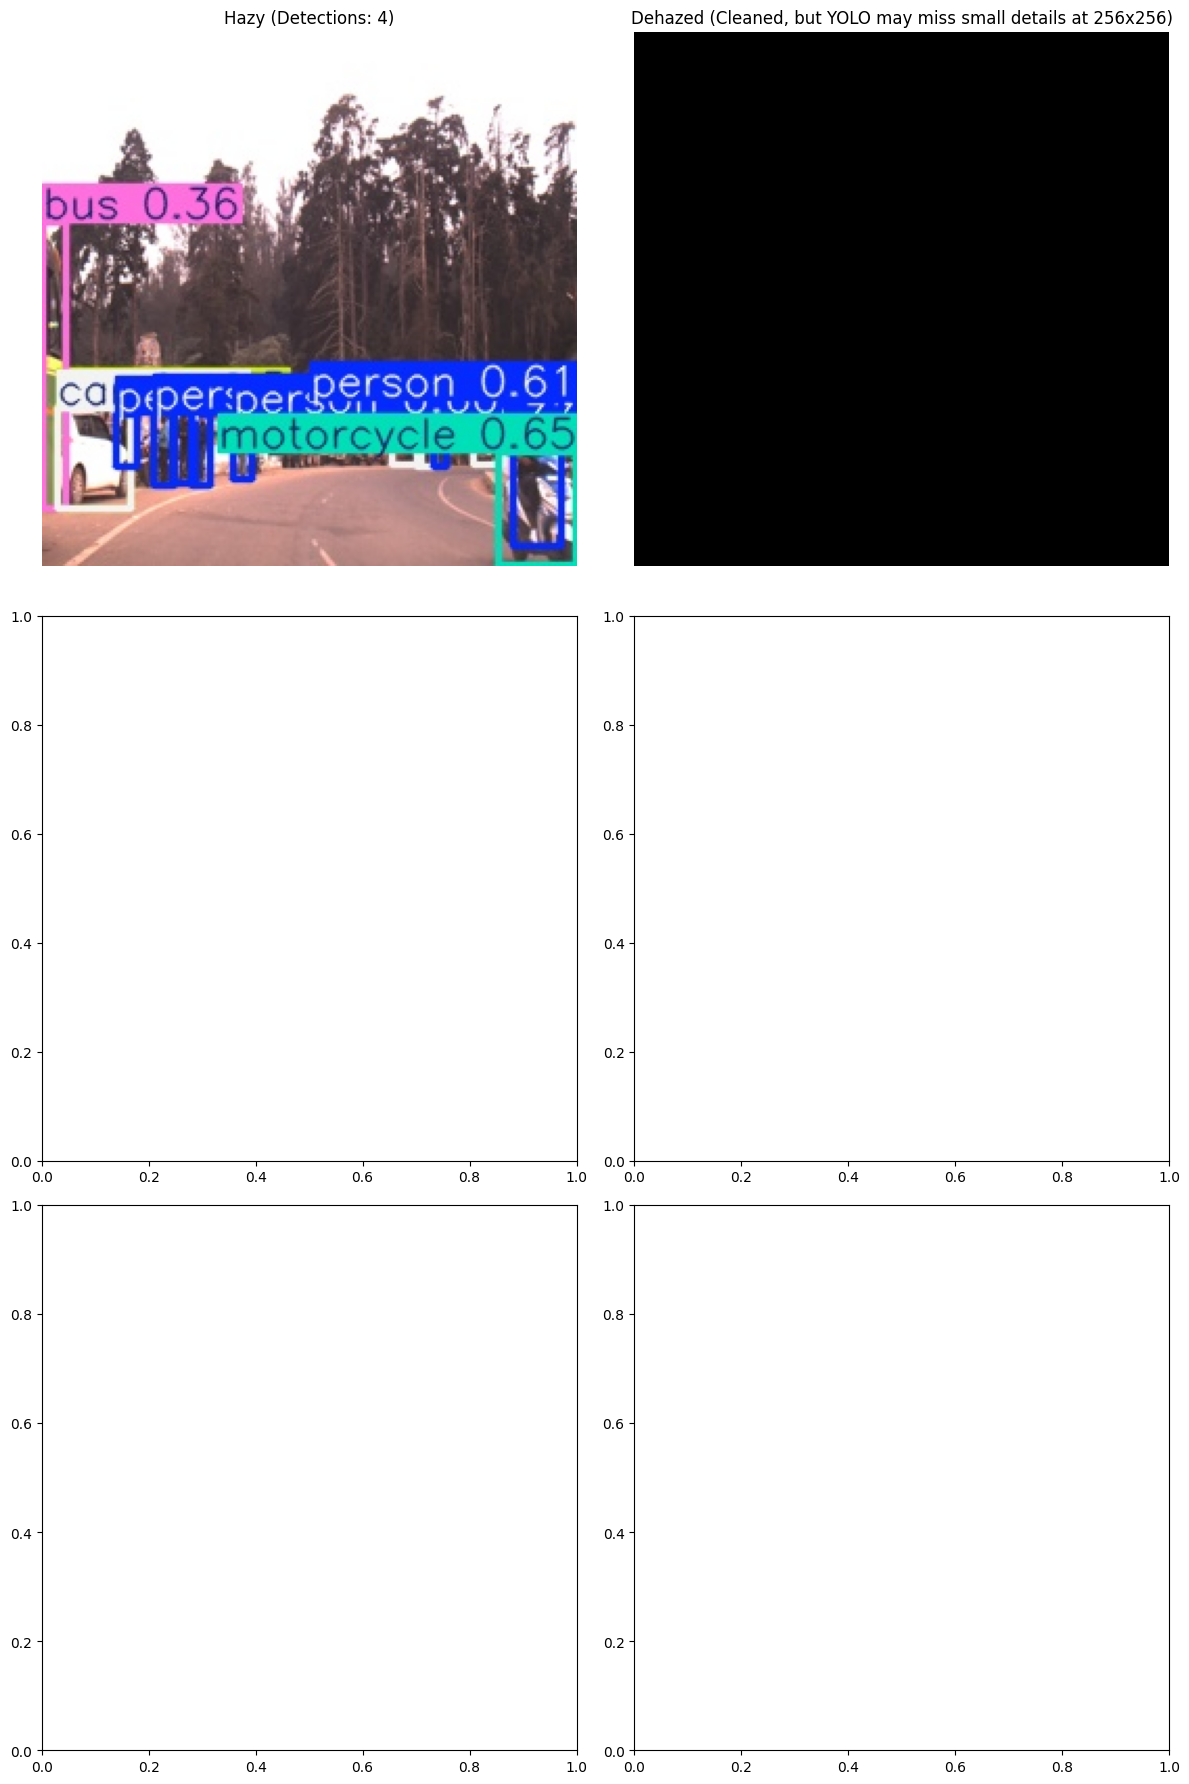

In [33]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

results_dir = "/kaggle/working/final_results"
hazy_preds_dir = os.path.join(results_dir, "yolov8_detections_fullres/hazy_full")
dehazed_preds_dir = os.path.join(results_dir, "yolov8_detections_fullres/dehazed_full")

# Get the saved YOLO images (they are named after the original images)
hazy_imgs = sorted(glob.glob(os.path.join(hazy_preds_dir, '*.jpg')))[:3] # Look at first 3

print("🖼️ Displaying YOLOv8 Detections Side-by-Side...")
print("Look closely: The 'Hazy' images likely have boxes around fog/noise (False Positives).")

fig, axes = plt.subplots(3, 2, figsize=(12, 18))

for i, hazy_path in enumerate(hazy_imgs):
    img_name = os.path.basename(hazy_path)
    dehazed_path = os.path.join(dehazed_preds_dir, img_name)
    
    # Load images
    img_hazy = Image.open(hazy_path)
    img_dehazed = Image.open(dehazed_path) if os.path.exists(dehazed_path) else Image.new('RGB', img_hazy.size)
    
    # Plot
    axes[i, 0].imshow(img_hazy)
    axes[i, 0].set_title(f"Hazy (Detections: {len(img_hazy.getbbox()) if img_hazy.getbbox() else 'See boxes'})", fontsize=12)
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(img_dehazed)
    axes[i, 1].set_title("Dehazed (Cleaned, but YOLO may miss small details at 256x256)", fontsize=12)
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

In [35]:
import os, glob, pandas as pd, torch
from ultralytics import YOLO
from PIL import Image
from torchvision import transforms
from torchvision.transforms import InterpolationMode

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ✅ THE FIX: Initialize with n_blocks=10 to match the saved weights exactly!
print("🔄 Reloading model with correct architecture (n_blocks=10)...")
model = Dehazzinggenerator(nfg=64, n_blocks=10, n_masks=10).to(device)

# Load weights strictly now
try:
    model.load_state_dict(torch.load("./saved_models/dehaze_aggan_gen_50epochs", map_location=device))
    print("✅ Model weights loaded successfully!")
except Exception as e:
    print(f"⚠️ Loading failed: {e}. We may need to retrain for 10 epochs.")

model.eval()

# Setup YOLOv8
print("⏳ Loading YOLOv8...")
yolo_model = YOLO('yolov8n.pt') 

results_dir = "/kaggle/working/final_results"
yolo_results_dir = os.path.join(results_dir, "yolov8_512x512_FIXED")
os.makedirs(yolo_results_dir, exist_ok=True)

idaw_base = "/kaggle/input/datasets/asmitchatterjee/idd-aw-raw/IDDAW/val/FOG/rgb"
fog_imgs = sorted(glob.glob(os.path.join(idaw_base, '**', '*.png'), recursive=True))[:5]

transform_norm = transforms.Compose([
    transforms.Resize((512, 512), interpolation=InterpolationMode.BICUBIC), 
    transforms.ToTensor(), 
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

detection_data = []
print("\n🔍 Running YOLOv8 at 512x512 Resolution with FIXED model...")

for img_path in fog_imgs:
    img_name = os.path.basename(img_path)
    
    # 1. Prepare Hazy Image at 512x512
    hazy_pil = Image.open(img_path).convert('RGB')
    hazy_512 = hazy_pil.resize((512, 512), Image.Resampling.BICUBIC)
    hazy_path_temp = os.path.join(yolo_results_dir, f"512_hazy_{img_name}")
    hazy_512.save(hazy_path_temp)
    
    # 2. Generate Dehazed Image at 512x512
    img_tensor = transform_norm(hazy_pil).unsqueeze(0).to(device)
    with torch.no_grad():
        out, _, _ = model(img_tensor)
        # Check if output is valid (not pure black)
        if out.abs().max() < 0.1:
            print(f"⚠️ Warning: Model output for {img_name} is very dark/black. Check weights.")
            
        out_raw = torch.clamp(out.squeeze(0) * 0.5 + 0.5, 0, 1).cpu()
    
    dehazed_pil = transforms.ToPILImage()(out_raw)
    dehazed_path_temp = os.path.join(yolo_results_dir, f"512_dehazed_{img_name}")
    dehazed_pil.save(dehazed_path_temp)
    
    # 3. Run YOLOv8
    results_hazy = yolo_model(hazy_path_temp, save=True, project=yolo_results_dir, name='hazy_512', verbose=False)
    results_dehazed = yolo_model(dehazed_path_temp, save=True, project=yolo_results_dir, name='dehazed_512', verbose=False)
    
    boxes_hazy = results_hazy[0].boxes
    boxes_dehazed = results_dehazed[0].boxes
    
    hazy_count = len(boxes_hazy) if boxes_hazy is not None else 0
    hazy_conf = boxes_hazy.conf.mean().item() if hazy_count > 0 else 0.0
    
    dehazed_count = len(boxes_dehazed) if boxes_dehazed is not None else 0
    dehazed_conf = boxes_dehazed.conf.mean().item() if dehazed_count > 0 else 0.0
    
    detection_data.append({
        'Image': img_name,
        'Hazy_Detections': hazy_count,
        'Hazy_Avg_Conf': f"{hazy_conf:.2f}",
        'Dehazed_Detections': dehazed_count,
        'Dehazed_Avg_Conf': f"{dehazed_conf:.2f}",
        'Improvement': '✅ Yes' if (dehazed_count >= hazy_count and dehazed_conf >= hazy_conf) else '️ Mixed'
    })

df_detection = pd.DataFrame(detection_data)
df_detection.to_csv(os.path.join(results_dir, "yolov8_512x512_FIXED.csv"), index=False)

print("\n📊 YOLOv8 512x512 Detection Comparison (FIXED):")
print(df_detection.to_string(index=False))

🔄 Reloading model with correct architecture (n_blocks=10)...
✅ Model weights loaded successfully!
⏳ Loading YOLOv8...

🔍 Running YOLOv8 at 512x512 Resolution with FIXED model...
Results saved to /kaggle/working/final_results/yolov8_512x512_FIXED/hazy_512-6
Results saved to /kaggle/working/final_results/yolov8_512x512_FIXED/dehazed_512-6
Results saved to /kaggle/working/final_results/yolov8_512x512_FIXED/hazy_512-7
Results saved to /kaggle/working/final_results/yolov8_512x512_FIXED/dehazed_512-7
Results saved to /kaggle/working/final_results/yolov8_512x512_FIXED/hazy_512-8
Results saved to /kaggle/working/final_results/yolov8_512x512_FIXED/dehazed_512-8
Results saved to /kaggle/working/final_results/yolov8_512x512_FIXED/hazy_512-9
Results saved to /kaggle/working/final_results/yolov8_512x512_FIXED/dehazed_512-9
Results saved to /kaggle/working/final_results/yolov8_512x512_FIXED/hazy_512-10
Results saved to /kaggle/working/final_results/yolov8_512x512_FIXED/dehazed_512-10

📊 YOLOv8 512x5